In [ ]:
# ======================================================================
# APTOS-2019 : download from Google Drive, unzip, and organize into
#              class-labeled folders (Class0..Class4) for train/val/test.
#
# Run this ONCE in Colab before the DR-XAI notebook. Afterwards point the
# notebook's cfg.BASE_DIR at OUT_ROOT and set cfg.DATASET_NAME = "APTOS".
# ======================================================================

# ---- 0. install + imports -------------------------------------------
!pip install -q gdown

import os, sys, zipfile, shutil, logging
from pathlib import Path
import pandas as pd

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)-7s | %(message)s",
                    datefmt="%H:%M:%S")
log = logging.getLogger("aptos")

# ---- 1. CONFIG -------------------------------------------------------
GDRIVE_FILE_ID = "<YOUR_DRIVE_FILE_ID>"   # your APTOS-2019_Dataset.zip
ZIP_PATH  = "/content/APTOS-2019_Dataset.zip"
UNZIP_DIR = "/content/APTOS-2019_Dataset"              # where the zip extracts to
OUT_ROOT  = "/content/APTOS2019_classfolders"          # final class-folder dataset
MODE      = "copy"                                     # "copy" (safe) or "move"
NUM_CLASSES = 5
EXT_CANDIDATES = (".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG")

# split -> (csv filename, image subfolder). Handles val/valid naming mismatch.
SPLITS = {
    "train":      {"csv": "train.csv", "img_dir": "train_images"},
    "validation": {"csv": "valid.csv", "img_dir": "val_images"},
    "test":       {"csv": "test.csv",  "img_dir": "test_images"},
}

# ---- 2. download + unzip --------------------------------------------
import gdown
if not os.path.exists(ZIP_PATH):
    log.info("Downloading APTOS-2019_Dataset.zip from Google Drive ...")
    gdown.download(f"https://drive.google.com/uc?id={GDRIVE_FILE_ID}",
                   ZIP_PATH, quiet=False)
else:
    log.info("Zip already present: %s", ZIP_PATH)

if not os.path.isdir(UNZIP_DIR) or not os.listdir(UNZIP_DIR):
    log.info("Unzipping ...")
    os.makedirs(UNZIP_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(UNZIP_DIR)
    log.info("Unzipped to %s", UNZIP_DIR)

# If the zip wrapped everything in one nested folder, descend into it so
# that SRC_ROOT directly contains train_images/ + the CSVs.
def _resolve_src(root: str) -> str:
    """Find the folder that actually holds train_images/ and the CSVs."""
    root = Path(root)
    for cand in [root] + [p for p in root.rglob("*") if p.is_dir()]:
        has_imgs = (cand / "train_images").is_dir()
        has_csv  = (cand / "train.csv").exists()
        if has_imgs and has_csv:
            return str(cand)
    return str(root)

SRC_ROOT = _resolve_src(UNZIP_DIR)
log.info("Resolved dataset root: %s", SRC_ROOT)
log.info("Contents: %s", sorted(os.listdir(SRC_ROOT))[:12])

# ---- 3. organizer ----------------------------------------------------
def find_image(img_dir: Path, id_code: str):
    """Return the actual image path for an id_code, trying known extensions."""
    direct = img_dir / id_code
    if direct.suffix and direct.exists():
        return direct
    for ext in EXT_CANDIDATES:
        p = img_dir / f"{id_code}{ext}"
        if p.exists():
            return p
    return None

def organize_split(split_name: str, csv_name: str, img_subdir: str) -> dict:
    """Copy/move every image of one split into its Class<label> subfolder."""
    csv_path = Path(SRC_ROOT) / csv_name
    img_dir  = Path(SRC_ROOT) / img_subdir
    assert csv_path.exists(),   f"CSV not found: {csv_path}"
    assert img_dir.is_dir(),    f"Image folder not found: {img_dir}"

    df = pd.read_csv(csv_path)
    df.columns = [c.strip().lower() for c in df.columns]
    assert {"id_code", "diagnosis"} <= set(df.columns), \
        f"{csv_name} needs columns id_code,diagnosis (got {list(df.columns)})"

    for c in range(NUM_CLASSES):
        (Path(OUT_ROOT) / split_name / f"Class{c}").mkdir(parents=True, exist_ok=True)

    counts  = {c: 0 for c in range(NUM_CLASSES)}
    missing = []
    op = shutil.copy2 if MODE == "copy" else shutil.move

    for _, row in df.iterrows():
        id_code = str(row["id_code"]).strip()
        label   = int(row["diagnosis"])
        if label not in counts:
            log.warning("[%s] unexpected label %s for %s — skipped", split_name, label, id_code)
            continue
        src = find_image(img_dir, id_code)
        if src is None:
            missing.append(id_code); continue
        shutil.copy2(str(src), str(Path(OUT_ROOT) / split_name / f"Class{label}" / src.name)) \
            if MODE == "copy" else shutil.move(str(src), str(Path(OUT_ROOT) / split_name / f"Class{label}" / src.name))
        counts[label] += 1

    total = sum(counts.values())
    log.info("[%s] %d images -> %s", split_name, total,
             {f"Class{k}": v for k, v in counts.items()})
    if missing:
        log.warning("[%s] %d id_codes had NO image file (first 10: %s)",
                    split_name, len(missing), missing[:10])
    return {"counts": counts, "total": total, "missing": missing}

# ---- 4. run + report -------------------------------------------------
summary = {s: organize_split(s, c["csv"], c["img_dir"]) for s, c in SPLITS.items()}

print("\n" + "=" * 66)
print("APTOS-2019 ORGANIZED — CLASS DISTRIBUTION PER SPLIT")
print("=" * 66)
print(f"{'split':<12}" + "".join(f"{'Class'+str(c):<9}" for c in range(NUM_CLASSES)) + f"{'TOTAL':>7}")
grand = 0
for split in SPLITS:
    counts = summary[split]["counts"]
    print(f"{split:<12}" + "".join(f"{counts[c]:<9}" for c in range(NUM_CLASSES))
          + f"{summary[split]['total']:>7}")
    grand += summary[split]["total"]
print("-" * 66)
print(f"{'GRAND TOTAL':<12}{'':<45}{grand:>7}")

total_missing = sum(len(summary[s]["missing"]) for s in SPLITS)
if total_missing:
    print(f"\n[!] {total_missing} id_codes had no matching image — check the unzip.")
else:
    print("\nAll id_codes matched an image file. No missing images.")

print(f"\nNext steps in the DR-XAI notebook:")
print(f"    cfg.BASE_DIR     = \"{OUT_ROOT}\"")
print(f"    cfg.DATASET_NAME = \"APTOS\"")
print(f"    cfg.LESION_MASK_DIR = None   # APTOS has no lesion masks (keep IDRiD for plausibility)")

Downloading...
From (original): https://drive.google.com/uc?id=<YOUR_DRIVE_FILE_ID>
From (redirected): https://drive.google.com/uc?id=<YOUR_DRIVE_FILE_ID>&confirm=t&uuid=<redacted>
To: /content/APTOS-2019_Dataset.zip
100%|██████████| 8.60G/8.60G [01:56<00:00, 74.1MB/s]



APTOS-2019 ORGANIZED — CLASS DISTRIBUTION PER SPLIT
split       Class0   Class1   Class2   Class3   Class4     TOTAL
train       1434     300      808      154      234         2930
validation  172      40       104      22       28           366
test        199      30       87       17       33           366
------------------------------------------------------------------
GRAND TOTAL                                                 3662

All id_codes matched an image file. No missing images.

Next steps in the DR-XAI notebook:
    cfg.BASE_DIR     = "/content/APTOS2019_classfolders"
    cfg.DATASET_NAME = "APTOS"
    cfg.LESION_MASK_DIR = None   # APTOS has no lesion masks (keep IDRiD for plausibility)


In [ ]:
import shutil

# Zip /content/APTOS2019_classfolders -> /content/APTOS2019_classfolders.zip
shutil.make_archive(
    "/content/APTOS2019_classfolders",   # output zip path (no .zip extension)
    "zip",                               # archive format
    "/content/APTOS2019_classfolders",   # folder to zip
)
print("Done: /content/APTOS2019_classfolders.zip")

Done: /content/APTOS2019_classfolders.zip


In [ ]:
# ======================================================================
# APTOS-2019 : Retinal ROI Cropping + Resize to 224x224
#
# Uses the SAME crop_retina() algorithm and parameters as the IDRiD
# pipeline (Hough circle -> contour fallback -> original, 2% margin),
# then the SAME resize stage (stretch to 224x224), so APTOS is
# preprocessed IDENTICALLY to your IDRiD dataset.
#
# INPUT  : /content/APTOS2019_classfolders/{train,validation,test}/Class0..4/*.png
# OUTPUT : /content/APTOS2019_classfolders_Cropped_224/{...}/Class0..4/*.png
#
# Run this in Colab AFTER the organize step. It writes to a NEW folder,
# keeping your uncropped APTOS copy safe.
# ======================================================================

# ---- installs (headless OpenCV avoids Colab GUI backend issues) ------
!pip install -q opencv-python-headless tqdm

import os, time, shutil, logging, zipfile
from pathlib import Path
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
np.random.seed(SEED)

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)-7s | %(message)s",
                    datefmt="%H:%M:%S", force=True)
logger = logging.getLogger("aptos_crop")


# ======================================================================
# CONFIG — identical crop parameters to the IDRiD pipeline
# ======================================================================
@dataclass
class Config:
    base_dir: Path = Path("/content")
    # Input = the class-folder dataset you just organized
    input_dirname: str = "APTOS2019_classfolders"
    # Cropped (variable size) intermediate, then resized 224 output
    cropped_dirname: str = "APTOS2019_classfolders_Cropped"
    resized_dirname: str = "APTOS2019_classfolders_Cropped_224"

    splits: Tuple[str, ...] = ("train", "validation", "test")
    image_exts: Tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

    # --- Hough Circle Transform (same as IDRiD) ---
    hough_dp: float = 1.2
    hough_min_dist_frac: float = 8.0
    hough_param1: int = 50
    hough_param2: int = 30
    hough_min_r_frac: float = 0.30
    hough_max_r_frac: float = 0.65

    # --- Contour fallback (same as IDRiD) ---
    tissue_thresh: int = 7
    min_contour_area_frac: float = 0.05

    # --- Safety margin & sanity guard (same as IDRiD) ---
    margin_frac: float = 0.02
    min_crop_frac: float = 0.20

    # --- Resize stage (same as IDRiD: stretch to 224x224) ---
    target_size: Tuple[int, int] = (224, 224)      # (width, height)
    aspect_mode: str = "stretch"                   # "stretch" or "pad"
    pad_color: Tuple[int, int, int] = (0, 0, 0)

    # --- Logs ---
    crop_log_name: str = "aptos_crop_log.csv"
    failed_log_name: str = "aptos_failed_images.csv"
    resize_log_name: str = "aptos_resize_log.csv"

    input_dir: Path = field(init=False)
    cropped_dir: Path = field(init=False)
    resized_dir: Path = field(init=False)

    def __post_init__(self) -> None:
        self.input_dir = self.base_dir / self.input_dirname
        self.cropped_dir = self.base_dir / self.cropped_dirname
        self.resized_dir = self.base_dir / self.resized_dirname


CFG = Config()
assert CFG.input_dir.is_dir(), f"Input not found: {CFG.input_dir} (run the organize step first)"
logger.info("Input   : %s", CFG.input_dir)
logger.info("Cropped : %s", CFG.cropped_dir)
logger.info("Resized : %s", CFG.resized_dir)


# ======================================================================
# CROP — verbatim from the IDRiD pipeline's crop_retina()
# ======================================================================
def crop_retina(img: np.ndarray, cfg: Config) -> Tuple[np.ndarray, str]:
    """Isolate the circular retinal ROI, preserving all retinal tissue.

    Three-tier strategy: Hough circle -> largest-contour enclosing circle ->
    original. A 2% safety margin is always added so peripheral lesions are
    never clipped. The image is cropped only (never resized here).
    Returns (crop, method) with method in {"Hough","Contour","Original"}.
    """
    h, w = img.shape[:2]
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Scale-adaptive Gaussian blur (kernel derived from sigma).
    sigma = max(h, w) / 300.0
    blur = cv2.GaussianBlur(gray, (0, 0), sigmaX=sigma)

    def _finalise(cx: int, cy: int, r: int, method: str) -> Optional[Tuple[np.ndarray, str]]:
        r = int(r * (1.0 + cfg.margin_frac))
        x1, y1 = max(0, cx - r), max(0, cy - r)
        x2, y2 = min(w, cx + r), min(h, cy + r)
        if (x2 - x1) > cfg.min_crop_frac * w and (y2 - y1) > cfg.min_crop_frac * h:
            return img[y1:y2, x1:x2], method
        return None

    # Hough Circle Transform.
    min_r = int(min(h, w) * cfg.hough_min_r_frac)
    max_r = int(min(h, w) * cfg.hough_max_r_frac)
    circles = cv2.HoughCircles(
        blur, cv2.HOUGH_GRADIENT, dp=cfg.hough_dp,
        minDist=min(h, w) / cfg.hough_min_dist_frac,
        param1=cfg.hough_param1, param2=cfg.hough_param2,
        minRadius=min_r, maxRadius=max_r,
    )
    if circles is not None:
        circles = np.uint16(np.around(circles))[0]
        cx0, cy0 = w / 2.0, h / 2.0
        best = min(circles, key=lambda c: (int(c[0]) - cx0) ** 2 + (int(c[1]) - cy0) ** 2)
        out = _finalise(int(best[0]), int(best[1]), int(best[2]), "Hough")
        if out is not None:
            return out

    # Contour fallback.
    _, mask = cv2.threshold(blur, cfg.tissue_thresh, 255, cv2.THRESH_BINARY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        largest = max(contours, key=cv2.contourArea)
        if cv2.contourArea(largest) > cfg.min_contour_area_frac * h * w:
            (cx, cy), r = cv2.minEnclosingCircle(largest)
            out = _finalise(int(cx), int(cy), int(r), "Contour")
            if out is not None:
                return out

    # Safe fallback — never crash, never clip.
    return img, "Original"


# ======================================================================
# RESIZE — verbatim from the IDRiD pipeline's resize_image()
# ======================================================================
def resize_image(img: np.ndarray, cfg: Config) -> np.ndarray:
    """Resize to target (stretch by default), area-interp when shrinking."""
    tw, th = cfg.target_size
    h, w = img.shape[:2]
    if cfg.aspect_mode == "pad":
        side = max(h, w)
        canvas = np.full((side, side, 3), cfg.pad_color, dtype=img.dtype)
        y0, x0 = (side - h) // 2, (side - w) // 2
        canvas[y0:y0 + h, x0:x0 + w] = img
        img, (h, w) = canvas, (side, side)
    interp = cv2.INTER_AREA if (tw < w or th < h) else cv2.INTER_CUBIC
    return cv2.resize(img, (tw, th), interpolation=interp)


# ======================================================================
# DRIVER — crop then resize, mirroring the folder hierarchy
# ======================================================================
def process_all(cfg: Config) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Crop + resize every image; write cropped and resized datasets."""
    for out_dir in (cfg.cropped_dir, cfg.resized_dir):
        if out_dir.exists():
            shutil.rmtree(out_dir)        # clean slate for reproducibility
        out_dir.mkdir(parents=True, exist_ok=True)

    # Build the full worklist first (accurate tqdm total).
    jobs: List[Tuple[str, str, Path]] = []
    for split in cfg.splits:
        split_dir = cfg.input_dir / split
        if not split_dir.is_dir():
            logger.warning("Split folder missing: %s", split_dir); continue
        for class_dir in sorted(p for p in split_dir.iterdir() if p.is_dir()):
            for img_path in sorted(class_dir.iterdir()):
                if img_path.suffix.lower() in cfg.image_exts:
                    jobs.append((split, class_dir.name, img_path))

    records, resize_records = [], []
    method_counts = {"Hough": 0, "Contour": 0, "Original": 0, "Failed": 0}

    for split, cls, src in tqdm(jobs, desc="Crop+Resize", unit="img"):
        crop_dst_dir = cfg.cropped_dir / split / cls
        rez_dst_dir = cfg.resized_dir / split / cls
        crop_dst_dir.mkdir(parents=True, exist_ok=True)
        rez_dst_dir.mkdir(parents=True, exist_ok=True)

        start = time.perf_counter()
        try:
            img = cv2.imread(str(src))
            if img is None:
                raise ValueError("cv2.imread returned None (unreadable image).")
            crop, method = crop_retina(img, cfg)
            if not cv2.imwrite(str(crop_dst_dir / src.name), crop):
                raise IOError("cv2.imwrite (crop) failed.")
            resized = resize_image(crop, cfg)
            if not cv2.imwrite(str(rez_dst_dir / src.name), resized):
                raise IOError("cv2.imwrite (resize) failed.")
            elapsed = time.perf_counter() - start
            method_counts[method] += 1
            records.append(dict(Image=src.name, Split=split, Class=cls, Method=method,
                                CropW=crop.shape[1], CropH=crop.shape[0],
                                Time=round(elapsed, 4), Status="OK"))
            resize_records.append(dict(Image=src.name, Split=split, Class=cls,
                                       W=resized.shape[1], H=resized.shape[0], Status="OK"))
        except Exception as exc:                       # log and continue by design
            elapsed = time.perf_counter() - start
            method_counts["Failed"] += 1
            logger.warning("Failed on %s: %s", src.name, exc)
            records.append(dict(Image=src.name, Split=split, Class=cls, Method="Failed",
                                CropW=0, CropH=0, Time=round(elapsed, 4),
                                Status=f"ERROR: {exc}"))

    crop_log = pd.DataFrame(records)
    resize_log = pd.DataFrame(resize_records)
    failed = crop_log[crop_log["Status"] != "OK"].copy()

    crop_log.to_csv(cfg.base_dir / cfg.crop_log_name, index=False)
    resize_log.to_csv(cfg.base_dir / cfg.resize_log_name, index=False)
    if not failed.empty:
        failed.to_csv(cfg.base_dir / cfg.failed_log_name, index=False)

    # ---- report ----
    print("\n" + "=" * 62)
    print("APTOS-2019 CROP + RESIZE COMPLETE")
    print("=" * 62)
    print(f"Total images processed : {len(jobs)}")
    print(f"Crop method breakdown  : Hough={method_counts['Hough']}, "
          f"Contour={method_counts['Contour']}, Original={method_counts['Original']}, "
          f"Failed={method_counts['Failed']}")
    # per-split/class resized counts
    print("\nRESIZED (224x224) CLASS DISTRIBUTION:")
    print(f"{'split':<12}" + "".join(f"{'Class'+str(c):<9}" for c in range(5)) + f"{'TOTAL':>7}")
    grand = 0
    for split in cfg.splits:
        row_counts = []
        for c in range(5):
            d = cfg.resized_dir / split / f"Class{c}"
            n = len(list(d.glob("*"))) if d.is_dir() else 0
            row_counts.append(n)
        print(f"{split:<12}" + "".join(f"{n:<9}" for n in row_counts) + f"{sum(row_counts):>7}")
        grand += sum(row_counts)
    print("-" * 62)
    print(f"{'GRAND TOTAL':<12}{'':<45}{grand:>7}")
    if not failed.empty:
        print(f"\n[!] {len(failed)} image(s) failed — see {cfg.failed_log_name}")
    else:
        print("\nNo failures. Every image cropped and resized.")

    # ---- verify all outputs are exactly 224x224 ----
    bad = 0
    for split in cfg.splits:
        for c in range(5):
            d = cfg.resized_dir / split / f"Class{c}"
            if not d.is_dir():
                continue
            for p in list(d.glob("*"))[:9999]:
                im = cv2.imread(str(p))
                if im is None or im.shape[0] != 224 or im.shape[1] != 224:
                    bad += 1
    print(f"Size check: {'ALL 224x224 OK' if bad == 0 else f'{bad} images NOT 224x224'}")

    print(f"\nNext: point the DR-XAI notebook at the RESIZED folder:")
    print(f"    cfg.BASE_DIR     = \"{cfg.resized_dir}\"")
    print(f"    cfg.DATASET_NAME = \"APTOS\"")
    return crop_log, resize_log


CROP_LOG, RESIZE_LOG = process_all(CFG)

# ---- optional: zip the resized dataset for reuse ----
def zip_resized(cfg: Config) -> Path:
    zip_path = cfg.base_dir / (cfg.resized_dirname + ".zip")
    logger.info("Zipping %s ...", cfg.resized_dir.name)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for root, _, files in os.walk(cfg.resized_dir):
            for f in files:
                fp = Path(root) / f
                zf.write(fp, fp.relative_to(cfg.base_dir))
    logger.info("Wrote %s", zip_path)
    return zip_path

# Uncomment to also produce a downloadable zip:
zip_resized(CFG)

14:39:15 | INFO    | Input   : /content/APTOS2019_classfolders
14:39:15 | INFO    | Cropped : /content/APTOS2019_classfolders_Cropped
14:39:15 | INFO    | Resized : /content/APTOS2019_classfolders_Cropped_224


Crop+Resize:   0%|          | 0/3662 [00:00<?, ?img/s]


APTOS-2019 CROP + RESIZE COMPLETE
Total images processed : 3662
Crop method breakdown  : Hough=2159, Contour=1503, Original=0, Failed=0

RESIZED (224x224) CLASS DISTRIBUTION:
split       Class0   Class1   Class2   Class3   Class4     TOTAL
train       1434     300      808      154      234         2930
validation  172      40       104      22       28           366
test        199      30       87       17       33           366
--------------------------------------------------------------
GRAND TOTAL                                                 3662

No failures. Every image cropped and resized.


15:01:53 | INFO    | Zipping APTOS2019_classfolders_Cropped_224 ...


Size check: ALL 224x224 OK

Next: point the DR-XAI notebook at the RESIZED folder:
    cfg.BASE_DIR     = "/content/APTOS2019_classfolders_Cropped_224"
    cfg.DATASET_NAME = "APTOS"


15:02:03 | INFO    | Wrote /content/APTOS2019_classfolders_Cropped_224.zip


PosixPath('/content/APTOS2019_classfolders_Cropped_224.zip')

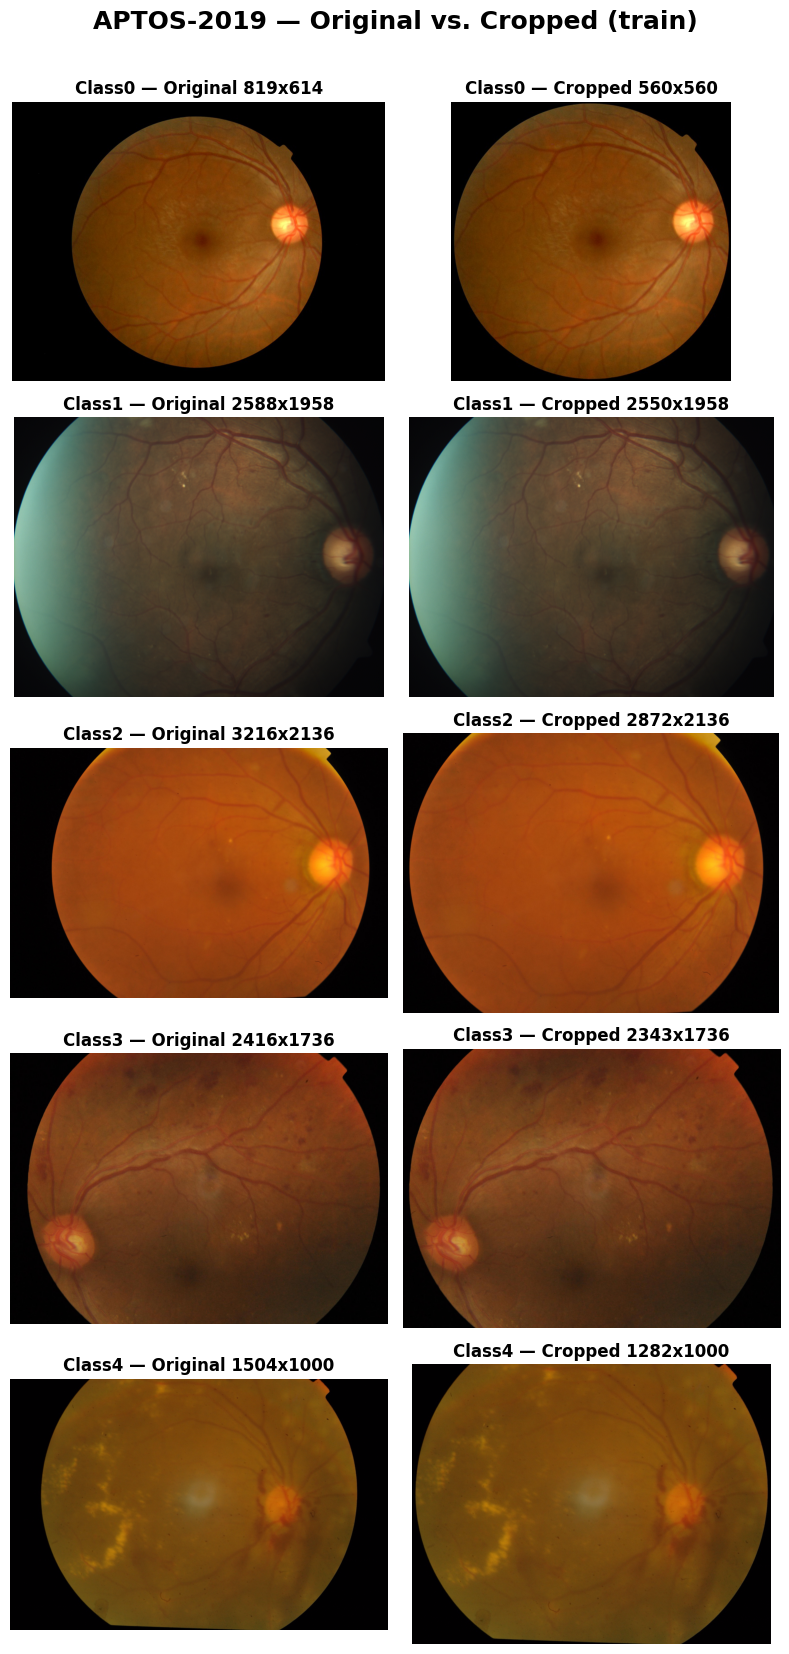

Saved: /content/APTOS_Original_vs_Cropped_per_class.png


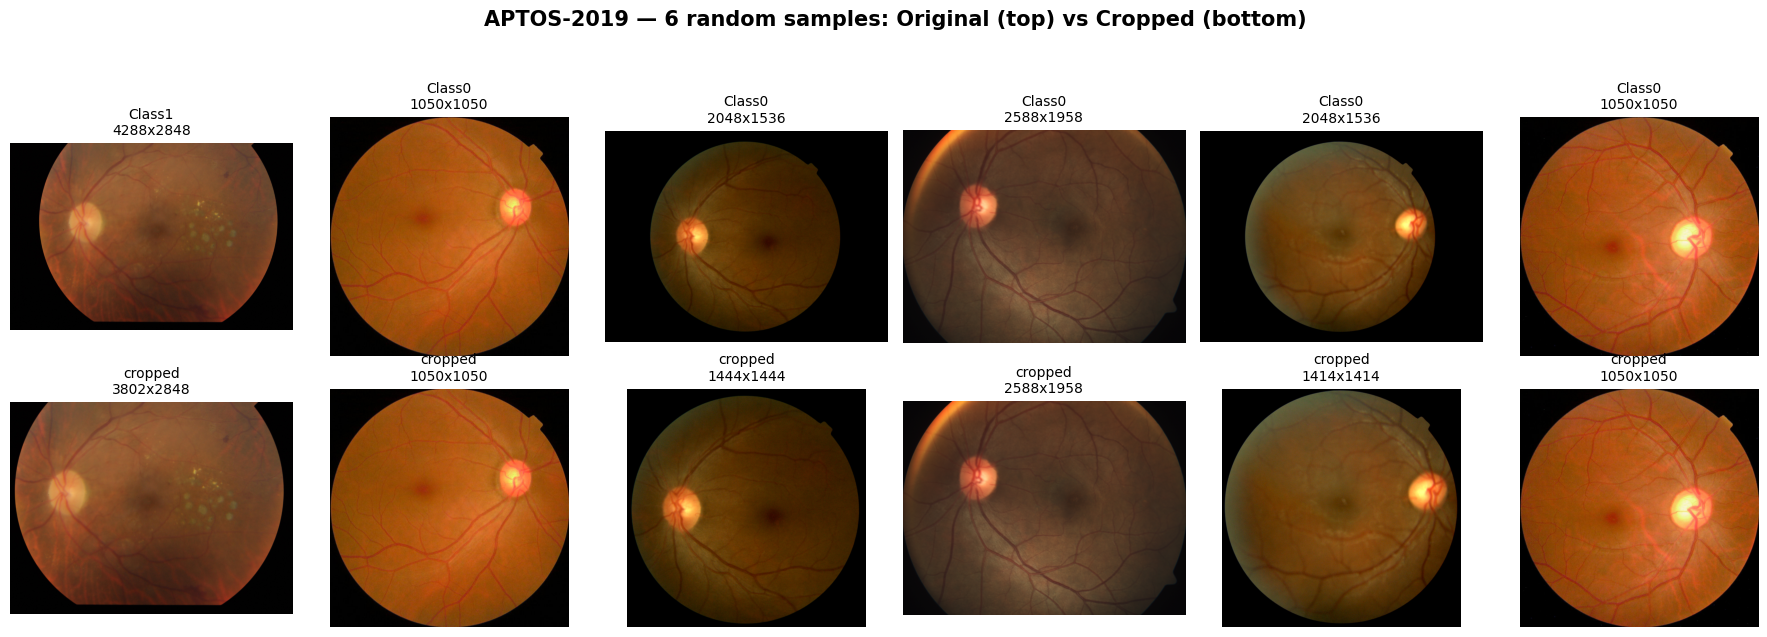

Saved: /content/APTOS_Original_vs_Cropped_random.png


In [ ]:
# ======================================================================
# APTOS-2019 : Visualise Original vs Cropped (before/after) images
#
# Run this AFTER APTOS_crop_resize.py, in the same Colab session (it reuses
# CFG). If running standalone, uncomment the CONFIG block below.
#
# Two figures:
#   (A) one image per class  (matches the IDRiD publication figure)
#   (B) N random before/after pairs (spot-check the cropping quality)
# ======================================================================

import random
from pathlib import Path
from typing import Optional

import cv2
import numpy as np
import matplotlib.pyplot as plt

# ---- standalone fallback config (uncomment if CFG is not already defined) ----
# from dataclasses import dataclass, field
# from typing import Tuple
# @dataclass
# class Config:
#     base_dir: Path = Path("/content")
#     input_dirname: str = "APTOS2019_classfolders"
#     cropped_dirname: str = "APTOS2019_classfolders_Cropped"
#     resized_dirname: str = "APTOS2019_classfolders_Cropped_224"
#     splits: Tuple[str, ...] = ("train", "validation", "test")
#     image_exts: Tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
#     figure_dpi: int = 200
#     input_dir: Path = field(init=False)
#     cropped_dir: Path = field(init=False)
#     def __post_init__(self):
#         self.input_dir = self.base_dir / self.input_dirname
#         self.cropped_dir = self.base_dir / self.cropped_dirname
# CFG = Config()

random.seed(42)


def _load_rgb(path: Path) -> Optional[np.ndarray]:
    """Read an image as RGB (matplotlib order), or None if unreadable."""
    bgr = cv2.imread(str(path))
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB) if bgr is not None else None


# ----------------------------------------------------------------------
# (A) One image per class — original vs cropped
# ----------------------------------------------------------------------
def show_one_per_class(cfg, split_key: str = "train") -> None:
    """Grid with one deterministic image per class: original | cropped."""
    src_split = cfg.input_dir / split_key
    class_dirs = sorted(p for p in src_split.iterdir() if p.is_dir())

    fig, axes = plt.subplots(len(class_dirs), 2, figsize=(8, 3.3 * len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.array([axes])
    fig.suptitle(f"APTOS-2019 — Original vs. Cropped ({split_key})",
                 fontsize=18, fontweight="bold", y=1.0)

    for row, class_dir in enumerate(class_dirs):
        imgs = sorted(p for p in class_dir.iterdir()
                      if p.suffix.lower() in cfg.image_exts)
        if not imgs:
            axes[row, 0].axis("off"); axes[row, 1].axis("off"); continue

        first = imgs[0]                                    # deterministic
        orig = _load_rgb(first)
        crop = _load_rgb(cfg.cropped_dir / split_key / class_dir.name / first.name)
        if crop is None:
            crop = orig

        axes[row, 0].imshow(orig)
        axes[row, 0].set_title(f"{class_dir.name} — Original {orig.shape[1]}x{orig.shape[0]}",
                               fontsize=12, fontweight="bold")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(crop)
        axes[row, 1].set_title(f"{class_dir.name} — Cropped {crop.shape[1]}x{crop.shape[0]}",
                               fontsize=12, fontweight="bold")
        axes[row, 1].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.99])
    out_path = cfg.base_dir / "APTOS_Original_vs_Cropped_per_class.png"
    fig.savefig(out_path, dpi=getattr(cfg, "figure_dpi", 200), bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


# ----------------------------------------------------------------------
# (B) N random before/after pairs — quality spot-check
# ----------------------------------------------------------------------
def show_random_pairs(cfg, n: int = 6, split_key: str = "train") -> None:
    """Show n random images as original (top row) vs cropped (bottom row)."""
    src_split = cfg.input_dir / split_key
    all_imgs = [p for cd in src_split.iterdir() if cd.is_dir()
                for p in cd.iterdir() if p.suffix.lower() in cfg.image_exts]
    if not all_imgs:
        print(f"No images found in {src_split}"); return
    picks = random.sample(all_imgs, min(n, len(all_imgs)))

    fig, axes = plt.subplots(2, len(picks), figsize=(3 * len(picks), 6.2))
    if len(picks) == 1:
        axes = axes.reshape(2, 1)
    fig.suptitle(f"APTOS-2019 — {len(picks)} random samples: Original (top) vs Cropped (bottom)",
                 fontsize=15, fontweight="bold", y=1.02)

    for col, img_path in enumerate(picks):
        cls = img_path.parent.name
        orig = _load_rgb(img_path)
        crop = _load_rgb(cfg.cropped_dir / split_key / cls / img_path.name)
        if crop is None:
            crop = orig
        axes[0, col].imshow(orig)
        axes[0, col].set_title(f"{cls}\n{orig.shape[1]}x{orig.shape[0]}", fontsize=10)
        axes[0, col].axis("off")
        axes[1, col].imshow(crop)
        axes[1, col].set_title(f"cropped\n{crop.shape[1]}x{crop.shape[0]}", fontsize=10)
        axes[1, col].axis("off")

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    out_path = cfg.base_dir / "APTOS_Original_vs_Cropped_random.png"
    fig.savefig(out_path, dpi=getattr(cfg, "figure_dpi", 200), bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")


# ----------------------------------------------------------------------
# Run both
# ----------------------------------------------------------------------
show_one_per_class(CFG, split_key="train")
show_random_pairs(CFG, n=6, split_key="train")

15:02:27 | INFO    | Input : /content/APTOS2019_classfolders_Cropped_224
15:02:27 | INFO    | Output: /content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE
15:02:27 | INFO    | Copying cropped-224 dataset -> APTOS2019_classfolders_Cropped_224_Aug_CLAHE


STEP 1/4 — GEOMETRIC AUGMENTATION (train only, per-class floor)


Aug Class1:   0%|          | 0/300 [00:00<?, ?it/s]

Aug Class3:   0%|          | 0/446 [00:00<?, ?it/s]

Aug Class4:   0%|          | 0/366 [00:00<?, ?it/s]


TRAIN class counts — BEFORE vs AFTER augmentation:


,Class,Original,Target,Generated,Multiplier,After(on disk)
0,Class0,1434,1434,0,1.00,1434
1,Class1,300,600,300,2.00,600
2,Class2,808,808,0,1.00,808
3,Class3,154,600,446,3.90,600
4,Class4,234,600,366,2.56,600



STEP 2/4 — CLAHE (ALL splits, ALL classes)


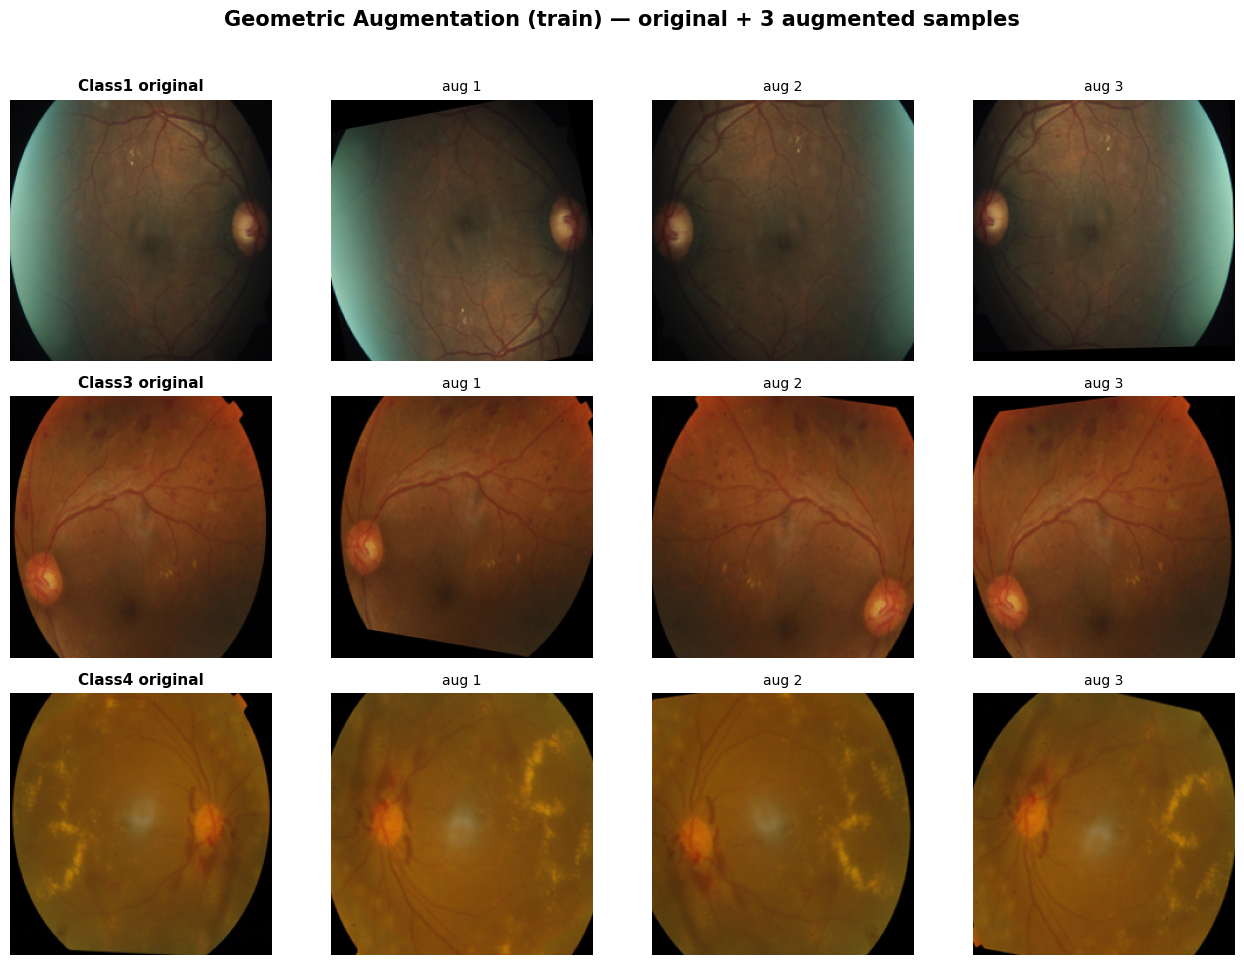

Saved: /content/APTOS_Augmentation_samples.png


CLAHE (all splits):   0%|          | 0/4774 [00:00<?, ?img/s]

15:03:12 | INFO    | CLAHE applied to 4774 images.



--- CLAHE COVERAGE CHECK ---
train (incl. augmented) : 4042
validation              : 366
test                    : 366
expected total          : 4774
CLAHE actually applied  : 4774
[OK] CLAHE applied to ALL 4774 images (4042 train incl. augmented + 366 val + 366 test).


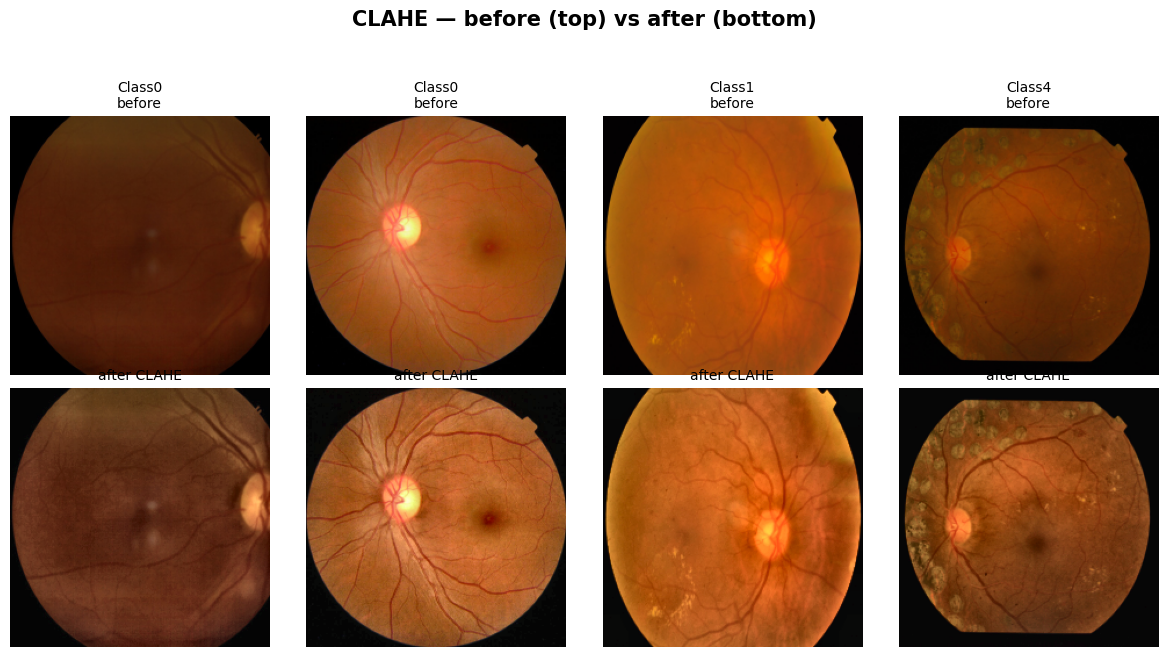

15:03:14 | INFO    | Zipping APTOS2019_classfolders_Cropped_224_Aug_CLAHE ...


Saved: /content/APTOS_CLAHE_before_after.png

STEP 3/4 — FINAL CLASS DISTRIBUTION (after aug + CLAHE)
split       Class0   Class1   Class2   Class3   Class4     TOTAL
train       1434     600      808      600      600         4042
validation  172      40       104      22       28           366
test        199      30       87       17       33           366
------------------------------------------------------------------
GRAND TOTAL                                                 4774

STEP 4/4 — ZIP


15:03:32 | INFO    | Wrote /content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE.zip



Done. Point the DR-XAI notebook at:
    cfg.BASE_DIR     = "/content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE"
    cfg.DATASET_NAME = "APTOS"
    cfg.LESION_MASK_DIR = None

Zip for reuse: /content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE.zip


In [ ]:
# ======================================================================
# APTOS-2019 : Geometric Augmentation (train only) + CLAHE (all splits)
#
# PIPELINE ORDER (matches your decision):
#   1. Copy the cropped-224 dataset to a new folder (originals kept safe).
#   2. GEOMETRIC AUGMENTATION on TRAIN ONLY, per-class floor to ~600 images
#      (cap 4x per class) for the imbalanced minority classes (1, 3, 4).
#      Augmented files are named <stem>_augNN.png so the notebook's leakage
#      audit can detect them.
#   3. CLAHE applied to ALL splits and ALL classes (train+val+test), as a
#      deterministic preprocessing step (contrast enhancement on L channel).
#   4. Before/after visual report + class-distribution tables.
#   5. Zip the final dataset.
#
# INPUT  : /content/APTOS2019_classfolders_Cropped_224
# OUTPUT : /content/APTOS2019_classfolders_Cropped_224_Aug_CLAHE
# ======================================================================

!pip install -q opencv-python-headless tqdm

import os, shutil, random, logging, zipfile
from pathlib import Path
from dataclasses import dataclass, field
from typing import Dict, List, Tuple

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s | %(levelname)-7s | %(message)s",
                    datefmt="%H:%M:%S", force=True)
logger = logging.getLogger("aptos_aug_clahe")


# ======================================================================
# CONFIG
# ======================================================================
@dataclass
class Config:
    base_dir: Path = Path("/content")
    input_dirname: str = "APTOS2019_classfolders_Cropped_224"
    output_dirname: str = "APTOS2019_classfolders_Cropped_224_Aug_CLAHE"

    splits: Tuple[str, ...] = ("train", "validation", "test")
    num_classes: int = 5
    image_exts: Tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

    # --- Augmentation (TRAIN ONLY) ---
    aug_floor: int = 600          # per-class target floor
    aug_cap: int = 4              # never exceed this multiple of the original count
    aug_classes: Tuple[int, ...] = (1, 3, 4)   # minority classes to augment

    # Geometric aug ranges (mild, lesion-safe: no heavy distortion)
    rot_max_deg: float = 12.0     # +/- rotation (reduced from 20 to limit black wedges)
    shift_frac: float = 0.06      # +/- translation as fraction of size
    zoom_range: Tuple[float, float] = (1.0, 1.12)  # always zoom IN so rotation gaps fall outside frame
    brightness_delta: float = 0.10  # +/- fraction on V channel
    p_hflip: float = 0.5
    p_vflip: float = 0.2          # vertical flip is plausible for fundus (less common)

    # --- CLAHE (ALL splits) ---
    clahe_clip: float = 2.0
    clahe_grid: Tuple[int, int] = (8, 8)

    # --- Logs / figures ---
    figure_dpi: int = 200

    input_dir: Path = field(init=False)
    output_dir: Path = field(init=False)

    def __post_init__(self) -> None:
        self.input_dir = self.base_dir / self.input_dirname
        self.output_dir = self.base_dir / self.output_dirname


CFG = Config()
assert CFG.input_dir.is_dir(), f"Input not found: {CFG.input_dir} (run crop+resize first)"
logger.info("Input : %s", CFG.input_dir)
logger.info("Output: %s", CFG.output_dir)


# ======================================================================
# Helpers
# ======================================================================
def list_images(d: Path, cfg: Config) -> List[Path]:
    return sorted(p for p in d.iterdir()
                  if p.is_file() and p.suffix.lower() in cfg.image_exts)


def class_counts(root: Path, split: str, cfg: Config) -> Dict[int, int]:
    out = {}
    for c in range(cfg.num_classes):
        d = root / split / f"Class{c}"
        out[c] = len(list_images(d, cfg)) if d.is_dir() else 0
    return out


# ======================================================================
# 1. Geometric augmentation (one random transform)
# ======================================================================
def augment_once(img: np.ndarray, cfg: Config, rng: random.Random) -> np.ndarray:
    """Apply ONE randomized, lesion-safe geometric+photometric transform."""
    h, w = img.shape[:2]

    # rotation + zoom via affine matrix around the centre
    angle = rng.uniform(-cfg.rot_max_deg, cfg.rot_max_deg)
    scale = rng.uniform(*cfg.zoom_range)
    M = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle, scale)
    # translation
    M[0, 2] += rng.uniform(-cfg.shift_frac, cfg.shift_frac) * w
    M[1, 2] += rng.uniform(-cfg.shift_frac, cfg.shift_frac) * h
    out = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_CUBIC,
                         borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    # horizontal / vertical flips
    if rng.random() < cfg.p_hflip:
        out = cv2.flip(out, 1)
    if rng.random() < cfg.p_vflip:
        out = cv2.flip(out, 0)

    # brightness jitter on V channel (HSV)
    if cfg.brightness_delta > 0:
        hsv = cv2.cvtColor(out, cv2.COLOR_BGR2HSV).astype(np.float32)
        factor = 1.0 + rng.uniform(-cfg.brightness_delta, cfg.brightness_delta)
        hsv[..., 2] = np.clip(hsv[..., 2] * factor, 0, 255)
        out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

    return out


def run_augmentation(cfg: Config) -> pd.DataFrame:
    """Copy dataset, then augment TRAIN minority classes to the per-class floor."""
    if cfg.output_dir.exists():
        shutil.rmtree(cfg.output_dir)
    logger.info("Copying cropped-224 dataset -> %s", cfg.output_dir.name)
    shutil.copytree(cfg.input_dir, cfg.output_dir)

    rng = random.Random(SEED)
    rows = []
    before = class_counts(cfg.input_dir, "train", cfg)

    for c in range(cfg.num_classes):
        orig = before[c]
        # target: floor, but never exceed cap*orig, never shrink, only aug listed classes
        if c in cfg.aug_classes and orig < cfg.aug_floor:
            target = min(cfg.aug_floor, orig * cfg.aug_cap)
        else:
            target = orig
        to_gen = max(0, target - orig)
        rows.append(dict(Class=f"Class{c}", Original=orig, Target=target,
                         Generated=to_gen, Multiplier=round(target / orig, 2) if orig else 0))

        if to_gen == 0:
            continue

        src_dir = cfg.output_dir / "train" / f"Class{c}"
        pool = list_images(src_dir, cfg)
        # round-robin over the real images so every eye is used evenly
        for i in tqdm(range(to_gen), desc=f"Aug Class{c}", leave=False):
            src = pool[i % len(pool)]
            img = cv2.imread(str(src))
            if img is None:
                continue
            aug = augment_once(img, cfg, rng)
            out_name = f"{src.stem}_aug{i:04d}.png"     # _augNN => leakage-audit visible
            cv2.imwrite(str(src_dir / out_name), aug)

    aug_tbl = pd.DataFrame(rows)
    return aug_tbl


# ======================================================================
# 2. CLAHE on ALL splits / ALL classes (applied in place on the output dir)
# ======================================================================
def apply_clahe_image(img: np.ndarray, cfg: Config) -> np.ndarray:
    """CLAHE on the L channel of LAB colour space (preserves colour)."""
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=cfg.clahe_clip, tileGridSize=cfg.clahe_grid)
    l2 = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l2, a, b)), cv2.COLOR_LAB2BGR)


def run_clahe(cfg: Config) -> int:
    """Apply CLAHE to every image in the output dataset (all splits/classes)."""
    all_imgs = [p for split in cfg.splits
                for c in range(cfg.num_classes)
                for p in list_images(cfg.output_dir / split / f"Class{c}", cfg)
                if (cfg.output_dir / split / f"Class{c}").is_dir()]
    n = 0
    for p in tqdm(all_imgs, desc="CLAHE (all splits)", unit="img"):
        img = cv2.imread(str(p))
        if img is None:
            continue
        cv2.imwrite(str(p), apply_clahe_image(img, cfg))
        n += 1
    return n


# ======================================================================
# 3. Before/after visual reports
# ======================================================================
def _rgb(p: Path):
    b = cv2.imread(str(p))
    return cv2.cvtColor(b, cv2.COLOR_BGR2RGB) if b is not None else None


def figure_augmentation(cfg: Config) -> None:
    """Show one original train image per augmented class + 3 of its augmentations.
    Read from a fresh copy of the pre-CLAHE state is not kept, so we regenerate
    augmentations on the fly purely for display (does not touch files)."""
    rng = random.Random(123)
    aug_classes = [c for c in cfg.aug_classes]
    fig, axes = plt.subplots(len(aug_classes), 4, figsize=(13, 3.2 * len(aug_classes)))
    if len(aug_classes) == 1:
        axes = np.array([axes])
    fig.suptitle("Geometric Augmentation (train) — original + 3 augmented samples",
                 fontsize=15, fontweight="bold", y=1.0)
    for row, c in enumerate(aug_classes):
        src_dir = cfg.input_dir / "train" / f"Class{c}"   # pre-aug originals
        imgs = list_images(src_dir, cfg)
        base = _rgb(imgs[0])
        axes[row, 0].imshow(base); axes[row, 0].set_title(f"Class{c} original",
                                                          fontsize=11, fontweight="bold")
        axes[row, 0].axis("off")
        bgr = cv2.imread(str(imgs[0]))
        for k in range(1, 4):
            aug = augment_once(bgr, cfg, rng)
            axes[row, k].imshow(cv2.cvtColor(aug, cv2.COLOR_BGR2RGB))
            axes[row, k].set_title(f"aug {k}", fontsize=10); axes[row, k].axis("off")
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    out = cfg.base_dir / "APTOS_Augmentation_samples.png"
    fig.savefig(out, dpi=cfg.figure_dpi, bbox_inches="tight"); plt.show()
    print(f"Saved: {out}")


def figure_clahe(cfg: Config, n: int = 4) -> None:
    """Show n images: pre-CLAHE (from input_dir) vs post-CLAHE (from output_dir)."""
    rng = random.Random(7)
    # sample from test (unaugmented, so filenames match across input/output)
    pool = [p for c in range(cfg.num_classes)
            for p in list_images(cfg.input_dir / "test" / f"Class{c}", cfg)]
    picks = rng.sample(pool, min(n, len(pool)))
    fig, axes = plt.subplots(2, len(picks), figsize=(3 * len(picks), 6.4))
    if len(picks) == 1:
        axes = axes.reshape(2, 1)
    fig.suptitle("CLAHE — before (top) vs after (bottom)",
                 fontsize=15, fontweight="bold", y=1.02)
    for col, p in enumerate(picks):
        cls = p.parent.name
        before = _rgb(p)
        after = _rgb(cfg.output_dir / "test" / cls / p.name)
        axes[0, col].imshow(before); axes[0, col].set_title(f"{cls}\nbefore", fontsize=10)
        axes[0, col].axis("off")
        axes[1, col].imshow(after); axes[1, col].set_title("after CLAHE", fontsize=10)
        axes[1, col].axis("off")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    out = cfg.base_dir / "APTOS_CLAHE_before_after.png"
    fig.savefig(out, dpi=cfg.figure_dpi, bbox_inches="tight"); plt.show()
    print(f"Saved: {out}")


# ======================================================================
# 4. Zip
# ======================================================================
def zip_output(cfg: Config) -> Path:
    zip_path = cfg.base_dir / (cfg.output_dirname + ".zip")
    logger.info("Zipping %s ...", cfg.output_dir.name)
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
        for root, _, files in os.walk(cfg.output_dir):
            for f in files:
                fp = Path(root) / f
                zf.write(fp, fp.relative_to(cfg.base_dir))
    logger.info("Wrote %s", zip_path)
    return zip_path


# ======================================================================
# RUN
# ======================================================================
print("=" * 66)
print("STEP 1/4 — GEOMETRIC AUGMENTATION (train only, per-class floor)")
print("=" * 66)
before_train = class_counts(CFG.input_dir, "train", CFG)
AUG_TBL = run_augmentation(CFG)
after_train = class_counts(CFG.output_dir, "train", CFG)

print("\nTRAIN class counts — BEFORE vs AFTER augmentation:")
plan = AUG_TBL.copy()
plan["After(on disk)"] = [after_train[c] for c in range(CFG.num_classes)]
try:
    from IPython.display import display
    display(plan)
except Exception:
    print(plan.to_string(index=False))

print("\n" + "=" * 66)
print("STEP 2/4 — CLAHE (ALL splits, ALL classes)")
print("=" * 66)
# Build the augmentation figure BEFORE CLAHE overwrites files (uses input_dir originals)
figure_augmentation(CFG)
n_clahe = run_clahe(CFG)
logger.info("CLAHE applied to %d images.", n_clahe)

# ---- HARD CHECK: CLAHE must cover EVERY image on disk (aug train + val + test) ----
train_after = sum(class_counts(CFG.output_dir, "train", CFG).values())
val_after   = sum(class_counts(CFG.output_dir, "validation", CFG).values())
test_after  = sum(class_counts(CFG.output_dir, "test", CFG).values())
expected = train_after + val_after + test_after
print("\n--- CLAHE COVERAGE CHECK ---")
print(f"train (incl. augmented) : {train_after}")
print(f"validation              : {val_after}")
print(f"test                    : {test_after}")
print(f"expected total          : {expected}")
print(f"CLAHE actually applied  : {n_clahe}")
assert n_clahe == expected, (
    f"CLAHE coverage mismatch: applied to {n_clahe} but {expected} images exist "
    f"(train {train_after} + val {val_after} + test {test_after}). "
    "Some images did NOT receive CLAHE.")
print(f"[OK] CLAHE applied to ALL {n_clahe} images "
      f"({train_after} train incl. augmented + {val_after} val + {test_after} test).")

figure_clahe(CFG, n=4)

print("\n" + "=" * 66)
print("STEP 3/4 — FINAL CLASS DISTRIBUTION (after aug + CLAHE)")
print("=" * 66)
print(f"{'split':<12}" + "".join(f"{'Class'+str(c):<9}" for c in range(CFG.num_classes)) + f"{'TOTAL':>7}")
grand = 0
for split in CFG.splits:
    cc = class_counts(CFG.output_dir, split, CFG)
    row_total = sum(cc.values()); grand += row_total
    print(f"{split:<12}" + "".join(f"{cc[c]:<9}" for c in range(CFG.num_classes)) + f"{row_total:>7}")
print("-" * 66)
print(f"{'GRAND TOTAL':<12}{'':<45}{grand:>7}")

print("\n" + "=" * 66)
print("STEP 4/4 — ZIP")
print("=" * 66)
ZIP_PATH = zip_output(CFG)

print(f"\nDone. Point the DR-XAI notebook at:")
print(f"    cfg.BASE_DIR     = \"{CFG.output_dir}\"")
print(f"    cfg.DATASET_NAME = \"APTOS\"")
print(f"    cfg.LESION_MASK_DIR = None")
print(f"\nZip for reuse: {ZIP_PATH}")